In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from sklearn.model_selection import StratifiedKFold, cross_validate

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


Load your training and testing datasets

In [2]:
project = Path.cwd().parent

data_dir = project / "Data-processed"

X_train = pd.read_csv(data_dir / "X_train.csv")
X_test = pd.read_csv(data_dir / "X_test.csv")

y_train = pd.read_csv(
    data_dir / "y_train.csv"
).iloc[:, 0]

y_test = pd.read_csv(
    data_dir / "y_test.csv"
).iloc[:, 0]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nTraining churn distribution:")
print(y_train.value_counts(normalize=True).round(3))

X_train: (5634, 19)
X_test: (1409, 19)
y_train: (5634,)
y_test: (1409,)

Training churn distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


Load the preprocessing pipeline

In [3]:
preprocessor = joblib.load(
    project / "models" / "preprocessor.pkl"
)

print("Preprocessing pipeline loaded successfully!")

Preprocessing pipeline loaded successfully!


Define the three machine learning models
Model 1: Logistic Regression
Logistic Regression is a strong starting model for binary classification problems such as churn prediction.

Model 2: Random Forest
Random Forest combines multiple decision trees to make predictions. It can capture nonlinear relationships between customer features.

Model 3: Gradient Boosting
Gradient Boosting builds trees sequentially, with later trees improving upon earlier ones.

In [4]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    )
}

print("Three models initialized successfully!")

Three models initialized successfully!


Train and compare models using cross-validation

In [5]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

results = []
pipelines = {}

for name, model in models.items():

    print(f"Evaluating {name}...")

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", model)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1
    )

    results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC_AUC": scores["test_roc_auc"].mean()
    })

    pipelines[name] = pipeline

results_df = pd.DataFrame(results)

display(results_df.round(4))

Evaluating Logistic Regression...
Evaluating Random Forest...
Evaluating Gradient Boosting...


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.8019,0.6521,0.5438,0.5924,0.8461
1,Random Forest,0.7996,0.6648,0.4963,0.5680,0.8407
2,Gradient Boosting,0.8033,0.6622,0.5291,0.5880,0.8482


What this code does:
- Trains and validates each model five times.
- Re-fits preprocessing within each training fold.
- Calculates the average performance across folds.
- Creates a comparison table for the three models.
These are cross-validation results, not final test results.

Visualize model performance

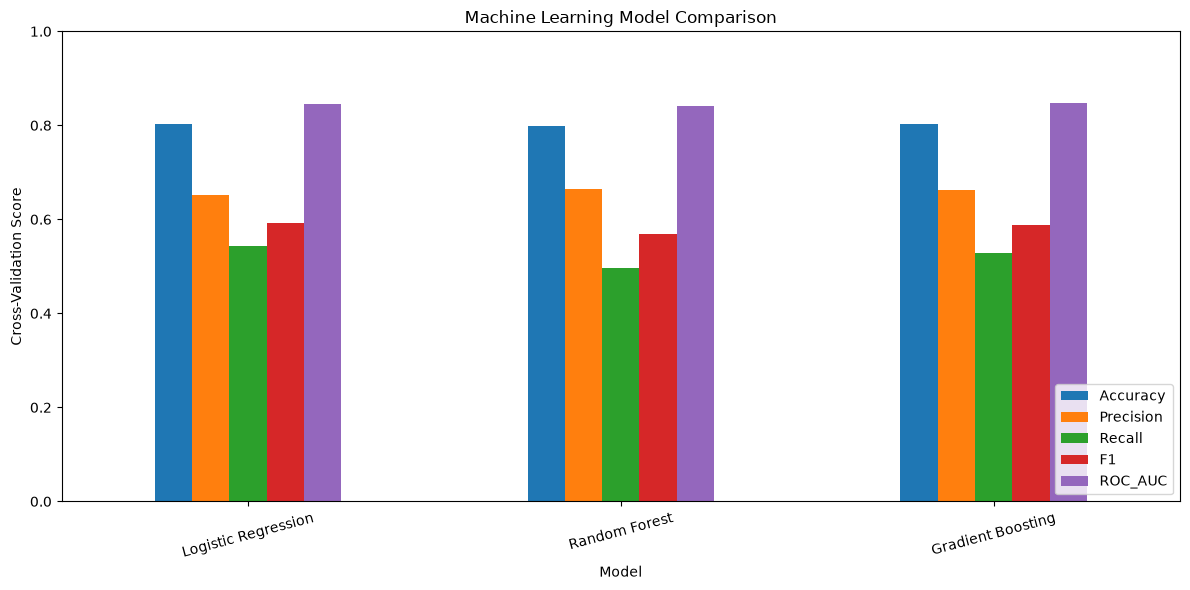

In [6]:
# Compare evaluation metrics
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC"
]

comparison = results_df.set_index("Model")[metrics]

comparison.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Cross-Validation Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

This will create a bar chart comparing the performance of all three models

For this project, we'll select the model with the highest cross-validation F1-score, while also examining recall and precision.

In your dataset, approximately 73.5% of customers did not churn. A model that predicts No for every customer could achieve roughly 73.5% accuracy while failing to identify any churned customers.

Select the best model

In [7]:
results_df = results_df.sort_values(
    by="F1",
    ascending=False
).reset_index(drop=True)

best_model_name = results_df.loc[0, "Model"]

best_pipeline = pipelines[best_model_name]

print("Best model:", best_model_name)

display(results_df.round(4))

Best model: Logistic Regression


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.8019,0.6521,0.5438,0.5924,0.8461
1,Gradient Boosting,0.8033,0.6622,0.5291,0.5880,0.8482
2,Random Forest,0.7996,0.6648,0.4963,0.5680,0.8407


Train the selected model on all training data

In [8]:
best_pipeline.fit(
    X_train,
    y_train
)

print(
    best_model_name,
    "trained successfully!"
)

Logistic Regression trained successfully!


Evaluate on the test dataset

In [9]:
y_pred = best_pipeline.predict(X_test)

y_prob = best_pipeline.predict_proba(
    X_test
)[:, 1]

test_results = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(
        y_test, y_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_pred, zero_division=0
    ),
    "F1": f1_score(
        y_test, y_pred, zero_division=0
    ),
    "ROC_AUC": roc_auc_score(y_test, y_prob)
}

print("Selected model:", best_model_name)

display(
    pd.DataFrame([test_results]).round(4)
)

Selected model: Logistic Regression


,Accuracy,Precision,Recall,F1,ROC_AUC
0,0.8055,0.6572,0.5588,0.604,0.842


Classification report

In [10]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Retained", "Churned"]
    )
)

              precision    recall  f1-score   support

    Retained       0.85      0.89      0.87      1035
     Churned       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



Confusion matrix

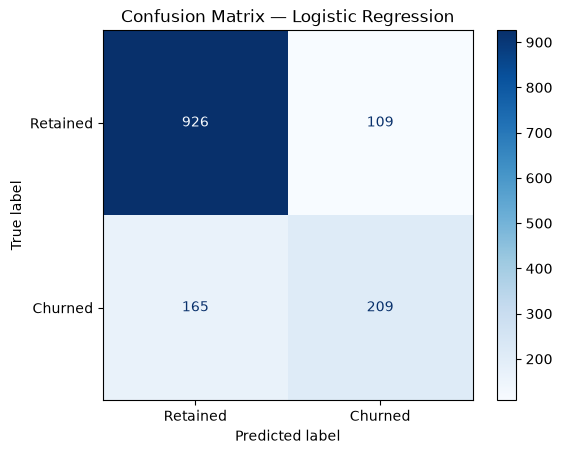

In [11]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Retained", "Churned"],
    cmap="Blues",
    values_format="d"
)

plt.title(f"Confusion Matrix — {best_model_name}")
plt.show()

Save your best model


In [12]:
models_dir = project / "models"
models_dir.mkdir(parents=True, exist_ok=True)

model_file = models_dir / "best_churn_model.pkl"

joblib.dump(best_pipeline, model_file)

print("Model saved successfully!")
print("File exists:", model_file.exists())
print("Location:", model_file.resolve())

Model saved successfully!
File exists: True
Location: C:\Users\yashr\OneDrive\Documents\AI CUSTOMER PREDICTION CHURN\models\best_churn_model.pkl


Save model comparison reports

In [13]:
report_dir = project / "Report"
report_dir.mkdir(parents=True, exist_ok=True)

results_df.to_csv(
    report_dir / "model_comparison.csv",
    index=False
)

pd.DataFrame([{
    "Model": best_model_name,
    **test_results
}]).to_csv(
    report_dir / "final_model_test_results.csv",
    index=False
)

print("Model reports saved successfully!")

Model reports saved successfully!


In [14]:
files_to_check = [
    models_dir / "best_churn_model.pkl",
    report_dir / "model_comparison.csv",
    report_dir / "final_model_test_results.csv"
]

for file in files_to_check:
    print(file.name, ":", file.exists())

best_churn_model.pkl : True
model_comparison.csv : True
final_model_test_results.csv : True
